In [1]:
%pip install xgboost lightgbm

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 577.7 kB/s eta 0:01:24
   ---------------------------------------- 0.5/48.9 MB 577.7 kB/s eta 0:01:24
    --------------------------------------- 0.8/48.9 MB 577.9 kB/s eta 0:01:24
    --------------------------------------- 0.8/48.9 MB 577.9 kB/s eta 0:01:24
    --------------------------------------- 1.0/48.9 MB 629.8 kB/s eta 0:01:17
    --------------------------------------- 1.0/48.9 MB 629.8 kB/s eta 0:01:17
   - -------------------------------

# SokoRadar 02: baselines, lead-lag, walk-forward and the final test
Runs **after** `01_eda_review.ipynb`. It follows the same plan (decision log in notebook 01): **train 2006-01 to 2024-12, test 2025-01 to 2026-09 (WFP only)**, estimated prices included and labelled.

| Step | Question | Evidence used |
|---|---|---|
| A | How good is "same as last month" / "same as last year"? | National series, shown **[EST]** (incl. estimated months) next to **[REAL]**; plus WFP county markets (real by construction) |
| B | Which crop's price predicts which? | WFP county markets only (no estimated national months); sensitivity with/without WFP `aggregate` rows |
| D1 | Does a model beat naive when evaluated walk-forward? | County market ledger; plus a 2006-vs-2019 training-start check |
| D2b | Can a rank-based alert beat chance and a "persistence" rule? | Same as D1 |
| D3 | Final test on 2025-2026, run once | County market ledger |

**Run order:** 01 first (writes `output/modelling/handoff/`), then this notebook. Nothing here is committed to git.

In [2]:
import json, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25})

# ---- same loader as notebook 01 ----
XNAME = 'SokoRadar_County_2006_2024.xlsx'
here = Path.cwd()
ROOT = next((p for p in [here, *here.parents] if (p / 'output' / XNAME).exists()), None)
if ROOT is not None:                                   # repo layout
    DATA = ROOT / 'sokoradar_raw_data'
    IN = ROOT / 'output' / 'modelling' / 'handoff'
else:                                                  # flat folder, e.g. CAPSTONE2
    ROOT = next((p for p in [here, *here.parents] if (p / XNAME).exists()), None)
    assert ROOT is not None, f'Could not find {XNAME} in {here} or any parent folder.'
    DATA = ROOT
    IN = ROOT / 'handoff'
assert (IN / 'meta.json').exists(), f'Handoff not found in {IN}. Run 01_eda_review.ipynb first.'

meta = json.load(open(IN/'meta.json')); CORE, TRAIN, TEST = meta['CORE'], meta['TRAIN'], meta['TEST']
def load_ts(f):
    d = pd.read_csv(IN/f, index_col=0); d.index = pd.PeriodIndex(d.index, freq='M'); return d
P = load_ts('national_prices.csv'); REAL = load_ts('national_real_flag.csv').astype(bool); THIN = load_ts('national_thin_flag.csv').astype(bool)
tr = slice(pd.Period(TRAIN[0]), pd.Period(TRAIN[1]))
led = pd.read_csv(IN/'real_ledger.csv'); led['month'] = pd.PeriodIndex(led['month'], freq='M')
led_act = pd.read_csv(IN/'real_ledger_actual_only.csv'); led_act['month'] = pd.PeriodIndex(led_act['month'], freq='M')   # sensitivity: priceflag actual only
print('ledger flags:', led.flag.value_counts().to_dict(), '| INCLUDE_AGGREGATE =', meta.get('INCLUDE_AGGREGATE'))
print(P.loc[tr].shape, '| ledger rows:', len(led), '| core:', len(CORE))

ledger flags: {'actual': 7073, 'aggregate': 2340} | INCLUDE_AGGREGATE = True
(228, 17) | ledger rows: 9413 | core: 4


## Step A. Baselines: naive and seasonal-naive
A model is only useful if it beats these two. **Naive** forecasts the last known price; **seasonal naive** forecasts the price from the same month last year. Errors are in log points (about percent / 100). MASE divides by the naive one-month error, so 1.0 means "as bad as naive".
- **A1 [EST] vs [REAL]:** national series scored twice. [EST] uses every month including estimated ones; [REAL] scores only months where both ends are real. Estimated months are smooth, so [EST] can flatter the baseline; use [REAL] as the bar.
- **A2:** the same baselines on each WFP county market series, with and without `aggregate` rows.

Share of months that are estimated: {'Dry Maize': '18%', 'Sorghum': '18%', 'Beans Rosecoco': '18%', 'Red Irish Potatoes': '18%'}


MAE_naive                          \
basis                [EST] incl. estimated [REAL] real months only   
series             h                                                 
Beans Rosecoco     1                 0.054                   0.052   
                   2                 0.080                   0.076   
                   3                 0.099                   0.096   
Dry Maize          1                 0.062                   0.056   
                   2                 0.101                   0.092   
                   3                 0.130                   0.121   
Red Irish Potatoes 1                 0.144                   0.141   
                   2                 0.224                   0.215   
                   3                 0.271                   0.263   
Sorghum            1                 0.052                   0.054   
                   2                 0.079                   0.082   
                   3                 0.092                   0.095   

                              MAE_seasonal                          \
basis                [EST] incl. estimated [REAL] real months only   
series             h                                                 
Beans Rosecoco     1                 0.161                   0.149   
                   2                 0.161                   0.149   
                   3                 0.161                   0.149   
Dry Maize          1                 0.285                   0.268   
                   2                 0.285                   0.268   
                   3                 0.285                   0.268   
Red Irish Potatoes 1                 0.350                   0.317   
                   2                 0.350                   0.317   
                   3                 0.350                   0.317   
Sorghum            1                 0.171                   0.180   
                   2                 0.171                   0.180   
                   3                 0.171                   0.180   

                             MASE_seasonal                          \
basis                [EST] incl. estimated [REAL] real months only   
series             h                                                 
Beans Rosecoco     1                 2.966                   2.859   
                   2                 2.966                   2.859   
                   3                 2.966                   2.859   
Dry Maize          1                 4.606                   4.785   
                   2                 4.606                   4.785   
                   3                 4.606                   4.785   
Red Irish Potatoes 1                 2.427                   2.251   
                   2                 2.427                   2.251   
                   3                 2.427                   2.251   
Sorghum            1                 3.270                   3.357   
                   2                 3.270                   3.357   
                   3                 3.270                   3.357   

                                   n_naive                          
basis                [EST] incl. estimated [REAL] real months only  
series             h                                                
Beans Rosecoco     1                 227.0                   186.0  
                   2                 226.0                   184.0  
                   3                 225.0                   182.0  
Dry Maize          1                 227.0                   186.0  
                   2                 226.0                   184.0  
                   3                 225.0                   182.0  
Red Irish Potatoes 1                 227.0                   183.0  
                   2                 226.0                   181.0  
                   3                 225.0                   179.0  
Sorghum            1                 227.0          

Market series scored: actual+aggregate 92 | actual only 57


actual+aggregate                                                  \
                     series MAE_naive MAE_seasonal MASE_naive MASE_seasonal   
crop     h                                                                    
Beans    1               28     0.066        0.227      1.000         3.179   
         2               28     0.090        0.227      1.409         3.179   
         3               28     0.111        0.227      1.780         3.179   
Maize    1               33     0.076        0.299      1.000         3.504   
         2               33     0.116        0.299      1.403         3.504   
         3               33     0.145        0.299      1.687         3.504   
Potatoes 1               23     0.164        0.325      1.000         1.945   
         2               23     0.240        0.325      1.511         1.945   
         3               23     0.276        0.325      1.776         1.945   
Sorghum  1                8     0.103        0.240      1.000         2.781   
         2                8     0.118        0.240      1.407         2.781   
         3                8     0.174        0.240      1.689         2.781   

           actual only                                                  
                series MAE_naive MAE_seasonal MASE_naive MASE_seasonal  
crop     h                                                              
Beans    1          16     0.062        0.201      1.000         3.192  
         2          16     0.092        0.201      1.476         3.192  
         3          16     0.119        0.201      1.832         3.192  
Maize    1          22     0.069        0.311      1.000         4.283  
         2          22     0.104        0.311      1.515         4.283  
         3          22     0.140        0.311      1.943         4.283  
Potatoes 1          14     0.181        0.382      1.000         2.222  
         2          14     0.241        0.382      1.556         2.222  
         3          14     0.303        0.382      1.794         2.222  
Sorghum  1           5     0.061        0.211      1.000         3.431  
         2           5     0.103        0.211      1.514         3.431  
         3           5     0.142        0.211      1.793         3.431

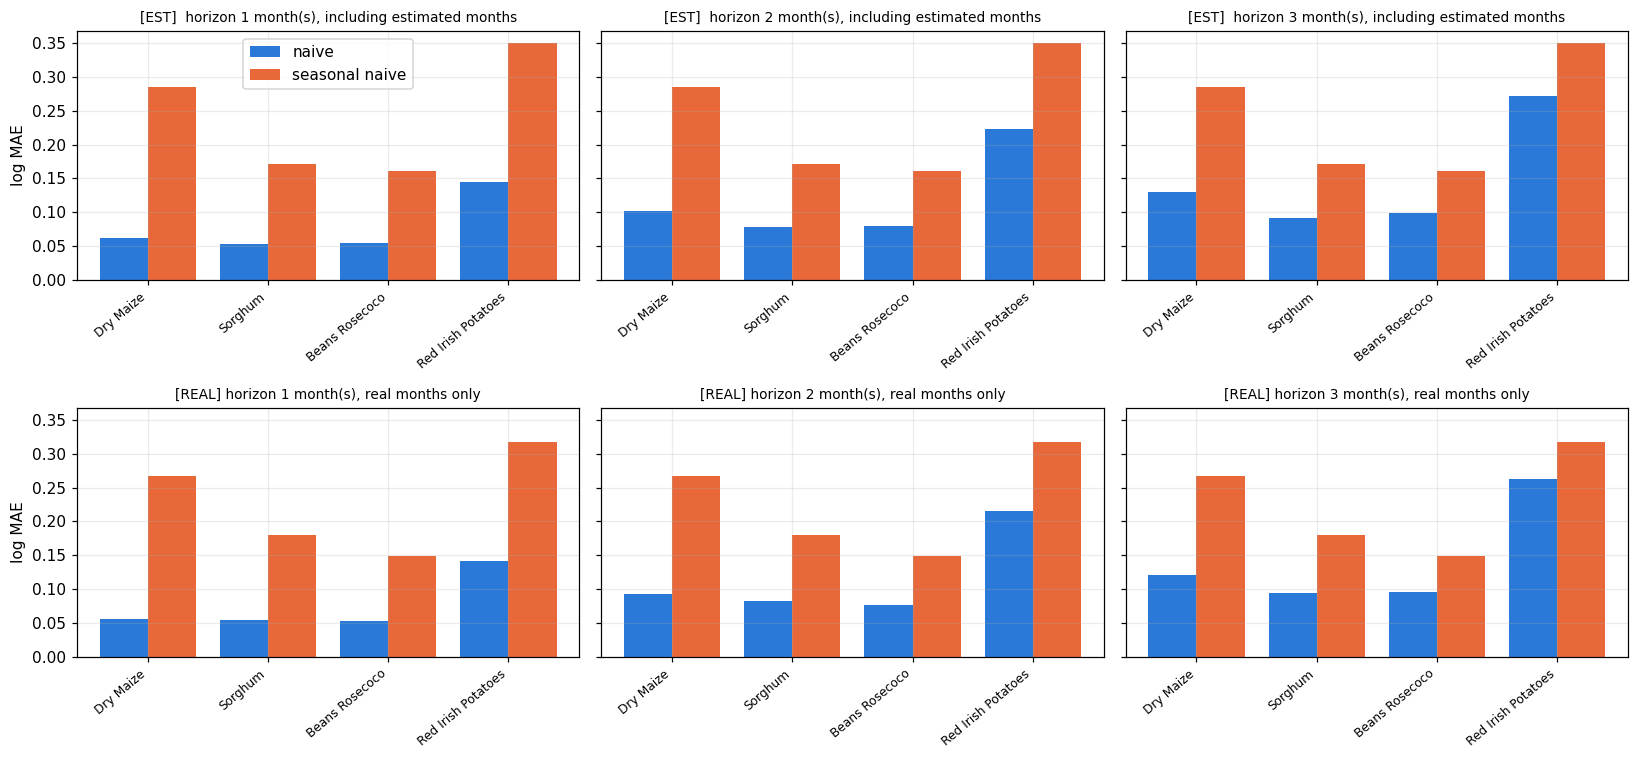

In [3]:
# ===== STEP A: BASELINES (naive, seasonal naive) =====
HS = (1, 2, 3)

def baseline_table(logp, real, name):
    logp = logp.copy(); real = real.reindex(logp.index).fillna(False)
    s = logp.where(real)                                   # keep real months only
    scale = (s - s.shift(1)).abs().mean()                  # MASE scale = naive h=1 error (real pairs)
    rows = []
    for h in HS:
        y = s.shift(-h)                                    # target at t+h
        naive_f = s                                        # naive: last real value
        seas_f = s.shift(12 - h)                           # seasonal naive: t+h-12
        e_n = (y - naive_f).abs().dropna()
        e_s = (y - seas_f).abs().dropna()
        rows.append(dict(series=name, h=h, n_naive=len(e_n), n_seasonal=len(e_s),
                         MAE_naive=e_n.mean(), MAE_seasonal=e_s.mean(),
                         MASE_naive=e_n.mean()/scale if scale > 0 else np.nan,
                         MASE_seasonal=e_s.mean()/scale if scale > 0 else np.nan,
                         target_10pct=0.9*e_n.mean()))
    return pd.DataFrame(rows)

# --- A1. National series: [EST] including estimated months vs [REAL] real months only ---
ALL = pd.Series(True, index=P.loc[tr].index)
nat_est  = pd.concat([baseline_table(np.log(P.loc[tr, c]), ALL, c) for c in CORE]).assign(basis='[EST] incl. estimated')
nat_real = pd.concat([baseline_table(np.log(P.loc[tr, c]), REAL.loc[tr, c], c) for c in CORE]).assign(basis='[REAL] real months only')
nat = pd.concat([nat_est, nat_real]); nat['seasonal_worse'] = nat.MAE_seasonal > nat.MAE_naive
print('Share of months that are estimated:', {c: f'{1-REAL.loc[tr, c].mean():.0%}' for c in CORE})
display(nat.pivot_table(index=['series', 'h'], columns='basis', values=['MAE_naive', 'MAE_seasonal', 'MASE_seasonal', 'n_naive']).round(3))

# --- A2. WFP county market series (every month is a real market price): actual+aggregate vs actual only ---
def mkt_scores(ledger):
    tm = ledger[ledger.month <= pd.Period(TRAIN[1])].copy(); rows = []
    for (mk, cr, pt), g in tm.groupby(['market', 'crop', 'pricetype']):
        if g.month.nunique() < 24: continue
        full = pd.period_range(g.month.min(), g.month.max(), freq='M')
        s_ = np.log(g.set_index('month').kes_kg.reindex(full))
        t = baseline_table(s_, s_.notna(), f'{mk}|{cr}|{pt}'); t['crop'] = cr; rows.append(t)
    return pd.concat(rows) if rows else pd.DataFrame()
def mkt_summary(m):
    return m.groupby(['crop', 'h']).agg(series=('series', 'nunique'), MAE_naive=('MAE_naive', 'median'), MAE_seasonal=('MAE_seasonal', 'median'),
            MASE_naive=('MASE_naive', 'median'), MASE_seasonal=('MASE_seasonal', 'median')).round(3)
mkt = mkt_scores(led); mkt_act = mkt_scores(led_act)
print('Market series scored: actual+aggregate', mkt.series.nunique() if len(mkt) else 0, '| actual only', mkt_act.series.nunique() if len(mkt_act) else 0)
if len(mkt):
    display(pd.concat({'actual+aggregate': mkt_summary(mkt), 'actual only': mkt_summary(mkt_act)}, axis=1))

# --- A3. Plot: [EST] on the top row, [REAL] on the bottom row ---
fig, axs = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
for r_, (b_, tt) in enumerate([('[EST] incl. estimated', 'including estimated months'), ('[REAL] real months only', 'real months only')]):
    for ax, h in zip(axs[r_], HS):
        d = nat[(nat.h == h) & (nat.basis == b_)].set_index('series'); x = np.arange(len(d))
        ax.bar(x-.2, d.MAE_naive, .4, label='naive', color='#2a78d8'); ax.bar(x+.2, d.MAE_seasonal, .4, label='seasonal naive', color='#e8683a')
        ax.set_xticks(x); ax.set_xticklabels(d.index, rotation=40, ha='right', fontsize=8); ax.set_title(f'{b_[:6]} horizon {h} month(s), {tt}', fontsize=9)
    axs[r_][0].set_ylabel('log MAE')
axs[0][0].legend(); plt.tight_layout(); plt.show()


## Step B. Lead-lag: which crop's price predicts which
For each ordered pair (cause, effect) we regress the effect crop's monthly price change on three lags of the cause crop's change, with market fixed effects and standard errors clustered by market. A Holm correction handles the many pairs tested. "Predicts" means the earlier move helps forecast the later one; it does not prove cause. Month fixed effects remove shocks common to all markets, so a result that survives them is not just a shared national shock. The era check asks whether the finding holds in both 2006-2018 and 2019-2024. The last table is the sensitivity to WFP `aggregate` rows.


=== Retail prices | month fixed effects: False ===


,cause,effect,n,markets,sum_coef,best_lag,p,p_holm,predicts
0,Potatoes,Beans,227,22,0.069,1,0.000,0.000,YES
1,Sorghum,Potatoes,82,14,-0.317,2,0.000,0.000,YES
2,Sorghum,Maize,85,15,-0.355,3,0.000,0.000,YES
3,Beans,Maize,609,27,0.610,1,0.000,0.001,YES
4,Potatoes,Sorghum,78,11,-0.183,1,0.002,0.016,YES
5,Maize,Potatoes,201,22,-0.583,2,0.014,0.100,weak (fails Holm)
6,Beans,Potatoes,223,22,-1.054,2,0.053,0.315,no
7,Sorghum,Beans,90,15,-0.090,2,0.054,0.315,no
8,Potatoes,Maize,201,22,0.237,1,0.099,0.395,no
9,Maize,Beans,612,27,0.107,3,0.106,0.395,no



=== Retail prices | month fixed effects: True ===


,cause,effect,n,markets,sum_coef,best_lag,p,p_holm,predicts
0,Sorghum,Maize,85,15,-0.438,2,0.001,0.011,YES
1,Potatoes,Beans,227,22,0.055,1,0.003,0.029,YES
2,Potatoes,Maize,201,22,0.302,1,0.003,0.032,YES
3,Beans,Potatoes,223,22,-0.183,2,0.020,0.177,weak (fails Holm)
4,Potatoes,Sorghum,78,11,-0.587,1,0.027,0.214,weak (fails Holm)
5,Beans,Maize,609,27,0.020,1,0.184,1.000,no
6,Maize,Potatoes,201,22,-0.344,2,0.196,1.000,no
7,Maize,Sorghum,85,13,-0.177,1,0.486,1.000,no
8,Sorghum,Potatoes,82,14,0.010,2,0.646,1.000,no
9,Sorghum,Beans,90,15,-0.025,2,0.694,1.000,no



=== Wholesale prices | month fixed effects: False ===


,cause,effect,n,markets,sum_coef,best_lag,p,p_holm,predicts
0,Maize,Potatoes,649,16,-0.624,1,0.000,0.000,YES
1,Beans,Maize,928,16,0.436,2,0.000,0.000,YES
2,Beans,Potatoes,651,18,-0.419,3,0.001,0.004,YES
3,Potatoes,Maize,653,16,0.075,2,0.004,0.018,YES
4,Potatoes,Beans,646,18,0.092,1,0.113,0.453,no
5,Potatoes,Sorghum,613,5,0.066,2,0.257,0.772,no
6,Maize,Beans,926,16,-0.049,3,0.407,0.814,no
7,Sorghum,Potatoes,612,5,-0.189,1,0.513,0.814,no


... (2 outputs left out)


=== Wholesale, month FE, 2006-2018 (WFP era) ===


,cause,effect,n,markets,sum_coef,best_lag,p,p_holm,predicts
0,Maize,Beans,699,5,-0.166,3,0.012,0.05,YES
1,Beans,Maize,700,5,0.011,2,0.057,0.17,no
2,Potatoes,Sorghum,549,5,0.010,3,0.260,0.52,no
3,Sorghum,Potatoes,548,5,-0.127,1,0.409,0.52,no



=== Wholesale, month FE, 2019-2024 (MoA era) ===


,cause,effect,n,markets,sum_coef,best_lag,p,p_holm,predicts
0,Maize,Potatoes,166,16,-0.416,1,0.000,0.002,YES
1,Beans,Maize,208,16,0.216,2,0.008,0.041,YES
2,Maize,Beans,207,16,0.202,3,0.011,0.044,YES
3,Beans,Potatoes,172,18,0.459,2,0.311,0.932,no
4,Potatoes,Beans,169,18,0.113,2,0.352,0.932,no
5,Potatoes,Maize,172,16,0.068,3,0.431,0.932,no


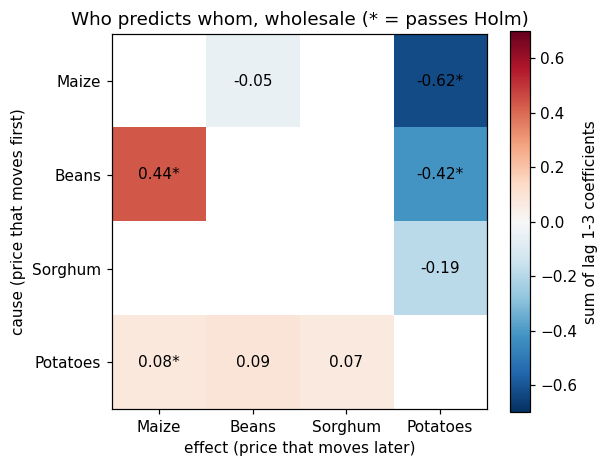


=== SENSITIVITY: actual+aggregate ledger vs actual-only ledger ===

Retail: not enough overlapping data in one of the two versions

Wholesale:


,cause,effect,n (+agg),markets (+agg),p (+agg),predicts (+agg),n (actual),markets (actual),p (actual),predicts (actual)
3,Maize,Potatoes,649,16,0.000,YES,649,16,0.000,YES
0,Beans,Maize,928,16,0.000,YES,928,16,0.000,YES
1,Beans,Potatoes,651,18,0.001,YES,651,18,0.001,YES
5,Potatoes,Maize,653,16,0.004,YES,653,16,0.004,YES
4,Potatoes,Beans,646,18,0.113,no,646,18,0.113,no
6,Potatoes,Sorghum,613,5,0.257,no,613,5,0.257,no
2,Maize,Beans,926,16,0.407,no,926,16,0.407,no
7,Sorghum,Potatoes,612,5,0.513,no,612,5,0.513,no


Step B uses county market prices only, so it contains NO estimated national months. The national maize/beans test with [EST] vs [REAL] is in notebook 01, section 8.


In [4]:
# ===== STEP B: LEAD-LAG (which crop's price predicts which) =====
import itertools, statsmodels.api as sm
CROPS = ['Maize', 'Beans', 'Sorghum', 'Potatoes']

def build_panel(pricetype='Retail', start=None, end=None, ledger=None):
    L0 = led if ledger is None else ledger
    d = L0[(L0.pricetype == pricetype) & (L0.month >= pd.Period(start or TRAIN[0])) & (L0.month <= pd.Period(end or TRAIN[1]))]
    w = np.log(d.pivot_table(index=['market', 'month'], columns='crop', values='kes_kg', aggfunc='median'))
    out = []
    for m, g in w.groupby(level='market'):
        g = g.droplevel('market')
        g = g.reindex(pd.period_range(g.index.min(), g.index.max(), freq='M'))
        dl = g.diff()                          # NaN unless both consecutive months are real
        dl['market'] = m; dl.index.name = 'month'; out.append(dl.reset_index())
    return pd.concat(out).sort_values(['market', 'month']).reset_index(drop=True)

def leadlag(panel, A, B, L=3, month_fe=False, min_obs=60, min_mkts=5):
    if A not in panel or B not in panel: return None
    g = panel.groupby('market')
    d = pd.DataFrame({'market': panel.market, 'month': panel.month, 'y': panel[B]})
    for k in range(1, L+1): d[f'A{k}'] = g[A].shift(k)
    for k in (1, 2):        d[f'B{k}'] = g[B].shift(k)
    d = d.dropna()
    if len(d) < min_obs or d.market.nunique() < min_mkts: return None
    cols = [c for c in d.columns if c not in ('market', 'month')]
    d[cols] = d[cols] - d.groupby('market')[cols].transform('mean')              # market fixed effects
    if month_fe: d[cols] = d[cols] - d.groupby('month')[cols].transform('mean')  # remove common monthly shocks
    X = d[[c for c in cols if c != 'y']]
    m = sm.OLS(d.y, X).fit(cov_type='cluster', cov_kwds={'groups': pd.factorize(d.market)[0]})
    w = m.wald_test(', '.join(f'A{k}=0' for k in range(1, L+1)), use_f=True, scalar=True)
    return dict(cause=A, effect=B, n=len(d), markets=d.market.nunique(),
                sum_coef=sum(m.params[f'A{k}'] for k in range(1, L+1)),
                best_lag=int(np.argmax([abs(m.tvalues[f'A{k}']) for k in range(1, L+1)]))+1,
                p=float(w.pvalue))

def run_all(pricetype='Retail', month_fe=False, start=None, end=None, ledger=None):
    panel = build_panel(pricetype, start, end, ledger)
    res = [leadlag(panel, a, b, month_fe=month_fe) for a, b in itertools.permutations(CROPS, 2)]
    res = pd.DataFrame([r for r in res if r])
    if res.empty: return res
    res = res.sort_values('p').reset_index(drop=True)
    res['p_holm'] = np.minimum(1, (res.p * (len(res) - res.index)).cummax())
    res['predicts'] = np.where(res.p_holm < .05, 'YES', np.where(res.p < .05, 'weak (fails Holm)', 'no'))
    return res

tabs = {}
for pt in ('Retail', 'Wholesale'):
    for fe in (False, True):
        t = run_all(pt, fe); tabs[(pt, fe)] = t
        print(f'\n=== {pt} prices | month fixed effects: {fe} ===')
        display(t.round(3) if len(t) else 'not enough real overlapping data')

# Robustness: does the wholesale result hold in both eras? (month fixed effects on)
for lab, (a, b) in {'2006-2018 (WFP era)': ('2006-01', '2018-12'), '2019-2024 (MoA era)': ('2019-01', '2024-12')}.items():
    t = run_all('Wholesale', True, a, b)
    print(f'\n=== Wholesale, month FE, {lab} ===')
    display(t.round(3) if len(t) else 'not enough real overlapping data')

# Heatmap of summed lag effects (wholesale, no month FE). * = passes Holm.
t = tabs[('Wholesale', False)]
if len(t):
    H = t.pivot(index='cause', columns='effect', values='sum_coef').reindex(index=CROPS, columns=CROPS)
    S = t.assign(s=np.where(t.p_holm < .05, '*', '')).pivot(index='cause', columns='effect', values='s').reindex(index=CROPS, columns=CROPS)
    fig, ax = plt.subplots(figsize=(5.5, 4.5)); im = ax.imshow(H.values.astype(float), cmap='RdBu_r', vmin=-.7, vmax=.7)
    ax.set_xticks(range(4)); ax.set_xticklabels(CROPS); ax.set_yticks(range(4)); ax.set_yticklabels(CROPS); ax.grid(False)
    for i in range(4):
        for j in range(4):
            v = H.values[i, j]
            if pd.notna(v): ax.text(j, i, f'{v:.2f}{S.values[i,j] if pd.notna(S.values[i,j]) else ""}', ha='center', va='center')
    ax.set_xlabel('effect (price that moves later)'); ax.set_ylabel('cause (price that moves first)')
    plt.colorbar(im, label='sum of lag 1-3 coefficients'); ax.set_title('Who predicts whom, wholesale (* = passes Holm)'); plt.show()

# --- Sensitivity: does the answer change if WFP "aggregate" rows are left out? (month FE off) ---
print('\n=== SENSITIVITY: actual+aggregate ledger vs actual-only ledger ===')
for pt in ('Retail', 'Wholesale'):
    a_ = run_all(pt, False, ledger=led); b_ = run_all(pt, False, ledger=led_act)
    if len(a_) and len(b_):
        m_ = a_.merge(b_, on=['cause', 'effect'], how='outer', suffixes=(' (+agg)', ' (actual)'))
        print(f'\n{pt}:'); display(m_[['cause', 'effect', 'n (+agg)', 'markets (+agg)', 'p (+agg)', 'predicts (+agg)', 'n (actual)', 'markets (actual)', 'p (actual)', 'predicts (actual)']].sort_values('p (+agg)').round(3))
    else: print(f'\n{pt}: not enough overlapping data in one of the two versions')
print('Step B uses county market prices only, so it contains NO estimated national months. The national maize/beans test with [EST] vs [REAL] is in notebook 01, section 8.')

## Step D1. Walk-forward evaluation
Instead of one train/test split, we replay history: at each quarterly cut, train on everything up to the cut, forecast the next three months, then move forward. Features are the recent price changes, a 3-month momentum, month of year, rainfall and vegetation (NDVI), and optionally the lead crop's changes (maize <-> beans) from Step B. The model is a ridge regression whose forecasts are shrunk 50% toward "no change"; set `MODEL='gb'` to try gradient boosting. Lead features are kept only if they win on identical rows. Gain over naive is the number to watch. Everything here uses county market prices, so no estimated national months enter.

In [5]:
# ===== STEP D1: WALK-FORWARD EVALUATION =====
# Evidence: county market prices only (WFP actual + aggregate). No estimated national months are used here.
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
MODEL = 'ridge_half'          # 'gb' = gradient boosting | 'ridge_half' = ridge with forecasts shrunk by 50% toward 'no change'
norm = lambda s: s.str.lower().str.replace(r'[^a-z]', '', regex=True)
cty = pd.read_csv(DATA/'counties.csv'); cty['key'] = norm(cty.county)
cl = pd.read_csv(DATA/'county_climate_chirps_ndvi.csv', parse_dates=['month']); cl['month'] = cl.month.dt.to_period('M')
cl = cl.merge(cty[['pcode', 'key']], left_on='county_pcode', right_on='pcode')[['key', 'month', 'rain_3m_pct', 'ndvi_pct']]
OTHER = {'Maize': 'Beans', 'Beans': 'Maize'}                       # lead-lag finding: beans <-> maize

def make_data(H):
    parts = []
    for (mk, pt, co), g in led.groupby(['market', 'pricetype', 'admin2']):
        w = np.log(g.pivot_table(index='month', columns='crop', values='kes_kg', aggfunc='median'))
        w = w.reindex(pd.period_range(w.index.min(), w.index.max(), freq='M'))
        for cr in w.columns:
            if w[cr].notna().sum() < 18: continue
            s = w[cr]; d = pd.DataFrame({'d1': s.diff()})
            d['d1_l1'] = d.d1.shift(1); d['d1_l2'] = d.d1.shift(2); d['mom3'] = s - s.shift(3)
            d['y'] = s.shift(-H) - s; d['moy'] = d.index.month
            o = OTHER.get(cr)
            for k in (1, 2, 3): d[f'x{k}'] = w[o].diff().shift(k) if (o in w.columns) else np.nan
            d['market'], d['crop'], d['ptype'], d['key'] = mk, cr, pt, norm(pd.Series([co]))[0]
            parts.append(d.reset_index().rename(columns={'index': 'month'}))
    D = pd.concat(parts).merge(cl, on=['key', 'month'], how='left')
    D['crop_code'] = D.crop.astype('category').cat.codes; D['pt_code'] = (D.ptype == 'Retail').astype(int)
    return D

BASE = ['d1', 'd1_l1', 'd1_l2', 'mom3', 'moy', 'rain_3m_pct', 'ndvi_pct', 'crop_code', 'pt_code']
LEAD = ['x1', 'x2', 'x3']
def fit_pred(tr_, te_, feats):
    if MODEL == 'gb':
        m = HistGradientBoostingRegressor(max_depth=2, learning_rate=.03, max_iter=80, min_samples_leaf=40,
                                          l2_regularization=5, random_state=0, categorical_features=[feats.index('crop_code')])
        m.fit(tr_[feats], tr_.y); return m.predict(te_[feats])
    X = tr_[feats].fillna(0); sc = StandardScaler().fit(X)
    m = Ridge(alpha=50).fit(sc.transform(X), tr_.y)
    return 0.5*m.predict(sc.transform(te_[feats].fillna(0)))

def walk_forward(D, feats, H, cuts, since=None):
    """Train on origins whose target ends by the cut; test on the next 3 months of origins."""
    D = D.dropna(subset=[f for f in feats if f not in LEAD] + ['y'])
    out = []
    for c in cuts:
        tr_ = D[(D.month <= c - H) & (D.month >= pd.Period(since, 'M') if since else True)]; te_ = D[(D.month > c) & (D.month <= c + 3)]
        if len(tr_) < 80 or len(te_) < 10: continue
        te_ = te_.assign(pred=fit_pred(tr_, te_, feats), cut=str(c)); out.append(te_)
    return pd.concat(out) if out else pd.DataFrame()

def summarize(P_, label):
    g = P_.groupby('cut').apply(lambda d: pd.Series({'n': len(d), 'naive': d.y.abs().mean(), 'model': (d.y - d.pred).abs().mean()}))
    g['gain_%'] = 100*(1 - g.model/g.naive)
    tot = 100*(1 - (P_.y - P_.pred).abs().mean()/P_.y.abs().mean())
    print(f'{label}: mean gain per cut {g["gain_%"].mean():.1f}% | pooled gain {tot:.1f}% | cuts won {(g["gain_%"]>0).sum()}/{len(g)}')
    return g

CUTS = [pd.Period('2012-12', 'M') + 3*i for i in range(40)]     # quarterly cuts, Dec 2012 - Sep 2022 (needs the 2006 history)
dev = {}
for H in (1, 2, 3):
    D = make_data(H); D = D[D.month <= pd.Period(TRAIN[1])]       # development uses train window only
    # STEP 1: lead-lag features, compared on identical rows (maize and beans rows that have the lead features)
    sub = D[D.crop.isin(OTHER) & D[LEAD].notna().all(axis=1)]
    a = walk_forward(sub, BASE, H, CUTS); b = walk_forward(sub, BASE + LEAD, H, CUTS)
    print(f'\n--- H={H}: lead-lag test on {len(sub)} maize/beans rows ---')
    if len(a) and len(b):
        ga, gb = summarize(a, 'without lead'), summarize(b, 'with lead   ')
        keep = (gb['gain_%'].mean() > ga['gain_%'].mean()) and ((gb['gain_%'] > ga['gain_%']).mean() > .5)
        print('KEEP lead features:', keep)
    else: print('not enough rows for lead test'); keep = False
    # STEP 2: full walk-forward on all series with the chosen feature set
    feats = BASE + (LEAD if keep else [])
    P_ = walk_forward(D, feats, H, CUTS); dev[H] = (P_, feats)
    display(summarize(P_, f'ALL series, H={H}').round(3))
    print(P_.groupby('crop').apply(lambda d: 100*(1 - (d.y - d.pred).abs().mean()/d.y.abs().mean())).round(1).rename('gain_% by crop').to_frame().T.to_string())


--- H=1: lead-lag test on 3210 maize/beans rows ---
without lead: mean gain per cut -0.5% | pooled gain 0.3% | cuts won 17/39
with lead   : mean gain per cut -0.4% | pooled gain 0.4% | cuts won 17/39
KEEP lead features: True
ALL series, H=1: mean gain per cut 0.2% | pooled gain 0.6% | cuts won 20/39


,n,naive,model,gain_%
cut,,,,
2012-12,64.0,0.096,0.096,0.162
2013-03,62.0,0.045,0.048,-6.222
2013-06,63.0,0.064,0.064,-0.603
2013-09,63.0,0.036,0.038,-4.195
2013-12,58.0,0.043,0.043,-0.257
2014-03,66.0,0.063,0.062,1.912
2014-06,63.0,0.056,0.055,1.590
2014-09,63.0,0.065,0.067,-2.605
2014-12,63.0,0.078,0.075,4.159


crop            Beans  Maize  Potatoes  Sorghum
gain_% by crop   -0.6    0.1       2.3     -0.7

--- H=2: lead-lag test on 3210 maize/beans rows ---
without lead: mean gain per cut 0.5% | pooled gain 1.9% | cuts won 19/38
with lead   : mean gain per cut 0.8% | pooled gain 2.2% | cuts won 21/38
KEEP lead features: True
ALL series, H=2: mean gain per cut 1.9% | pooled gain 2.1% | cuts won 27/39


,n,naive,model,gain_%
cut,,,,
2012-12,64.0,0.121,0.118,2.467
2013-03,62.0,0.067,0.068,-1.939
2013-06,63.0,0.094,0.089,5.397
2013-09,63.0,0.057,0.059,-3.939
2013-12,58.0,0.077,0.075,3.134
2014-03,64.0,0.107,0.107,-0.061
2014-06,65.0,0.089,0.086,4.272
2014-09,63.0,0.082,0.087,-6.121
2014-12,61.0,0.127,0.119,6.295


crop            Beans  Maize  Potatoes  Sorghum
gain_% by crop    1.6    1.1       4.1     -0.6

--- H=3: lead-lag test on 3210 maize/beans rows ---
without lead: mean gain per cut 1.1% | pooled gain 2.6% | cuts won 20/38
with lead   : mean gain per cut 1.4% | pooled gain 2.8% | cuts won 22/38
KEEP lead features: True
ALL series, H=3: mean gain per cut 2.8% | pooled gain 3.4% | cuts won 28/38


,n,naive,model,gain_%
cut,,,,
2012-12,63.0,0.144,0.138,3.991
2013-03,64.0,0.080,0.078,2.710
2013-06,61.0,0.114,0.102,10.246
2013-09,65.0,0.069,0.070,-1.335
2013-12,59.0,0.093,0.087,6.364
2014-03,64.0,0.132,0.138,-3.867
2014-06,65.0,0.111,0.113,-1.528
2014-09,63.0,0.098,0.101,-3.528
2014-12,59.0,0.139,0.133,3.906


crop            Beans  Maize  Potatoes  Sorghum
gain_% by crop    2.9    1.4       7.3     -0.4


### Does training from 2019 beat training from 2006? (decision D1)
The group plan is **train 2006-2024**. The worry is that 2006-2018 is an older market (and, nationally, WFP-scaled rather than MoA). This check uses the *same features, same test cuts and same model*; only the training start changes. Cuts start in Dec 2020 so a 2019 start has at least two years to learn from. Gain is the model's error cut versus "no change" (positive = better than naive). If 2006 is not clearly worse, keep 2006 because it has more seasons and shock episodes. Only a handful of cuts are available, so read the result as "no evidence that 2019 is better" rather than proof.

In [6]:
# ===== SENSITIVITY: training start 2006 vs 2019 (same test cuts) =====
CUT_S = [c for c in CUTS if c >= pd.Period('2020-12', 'M')]
rows = []
for H in (1, 2, 3):
    D = make_data(H); D = D[D.month <= pd.Period(TRAIN[1])]; feats = dev[H][1]
    for lab, since in (('train from 2006', None), ('train from 2019', '2019-01')):
        P_ = walk_forward(D, feats, H, CUT_S, since)
        if not len(P_): continue
        g = P_.groupby('cut').apply(lambda d: pd.Series({'naive': d.y.abs().mean(), 'model': (d.y - d.pred).abs().mean()}))
        rows.append(dict(H=H, training=lab, test_rows=len(P_), cuts=len(g), pooled_gain_pct=100*(1 - (P_.y - P_.pred).abs().mean()/P_.y.abs().mean()),
                         cuts_won=int((g.model < g.naive).sum())))
sens = pd.DataFrame(rows); display(sens.round(2))
print('Same cuts, same model. Pooled gain compares model error with naive error on identical rows.')

,H,training,test_rows,cuts,pooled_gain_pct,cuts_won
0,1,train from 2006,680,7,-0.44,3
1,1,train from 2019,680,7,-2.19,2
2,2,train from 2006,634,7,0.76,6
3,2,train from 2019,634,7,-1.11,4
4,3,train from 2006,594,7,4.93,7
5,3,train from 2019,594,7,4.56,5


Same cuts, same model. Pooled gain compares model error with naive error on identical rows.


## Step E. Model comparison: ARIMAX, ridge, LightGBM, XGBoost (against naive)
Until now the only learned model was a shrunk ridge. The supervisor asked which family of model to use, so here every candidate is scored **on identical rows**, with the **same walk-forward cuts**, and the **naive forecast stays on the table as the bar**.

* **E1, county market panel**: naive, ridge, ridge shrunk 50%, LightGBM, XGBoost. Each is run as one *pooled* model and as one model *per crop*.
* **E2, national series**: ARIMA vs **ARIMAX** (rain and NDVI as inputs), vs naive. ARIMAX is a single-series model, so it lives here and not in the panel.
* **E3, final test (2025-01 to 2026-09)**: models and settings fixed above, run once.
* **E4, automatic fallback**: a rolling monitor that switches a model back to naive when it has been losing.
* A **runtime** column is reported everywhere, because "computation power" matters if this is to run monthly.

In [7]:
# ===== STEP E1: COUNTY PANEL, MODELS ON IDENTICAL ROWS =====
import time, lightgbm as lgb, xgboost as xgb
warnings.filterwarnings('ignore')
def _ridge(a, shrink=1.0):
    def f(tr_, te_, feats):
        X = tr_[feats].fillna(0); sc = StandardScaler().fit(X)
        return shrink * Ridge(alpha=a).fit(sc.transform(X), tr_.y).predict(sc.transform(te_[feats].fillna(0)))
    return f
def _lgb(tr_, te_, feats):
    m = lgb.LGBMRegressor(n_estimators=120, learning_rate=.03, max_depth=3, num_leaves=7, min_child_samples=60, subsample=.8, subsample_freq=1,
                          colsample_bytree=.8, reg_lambda=5, random_state=0, n_jobs=2, verbose=-1)
    return m.fit(tr_[feats], tr_.y).predict(te_[feats])
def _xgb(tr_, te_, feats):
    m = xgb.XGBRegressor(n_estimators=120, learning_rate=.03, max_depth=3, min_child_weight=20, subsample=.8, colsample_bytree=.8,
                         reg_lambda=5, random_state=0, n_jobs=2, tree_method='hist')
    return m.fit(tr_[feats], tr_.y).predict(te_[feats])
MODELS = {'ridge': _ridge(50), 'ridge_half': _ridge(50, .5), 'lightgbm': _lgb, 'xgboost': _xgb}

def wf_models(D, feats, H, cuts, per_crop=False):
    """Same cuts and same rows for every model. Returns one frame with a pred_<model> column each, plus seconds per model."""
    D = D.dropna(subset=[f for f in feats if f not in LEAD] + ['y']); out = []; secs = {k: 0.0 for k in MODELS}
    for c in cuts:
        tr_ = D[D.month <= c - H]; te_ = D[(D.month > c) & (D.month <= c + 3)]
        if len(tr_) < 80 or len(te_) < 10: continue
        te_ = te_.assign(cut=str(c))
        for k, f in MODELS.items():
            t0 = time.time()
            if per_crop:
                p = pd.Series(0.0, index=te_.index)
                for cr, g in te_.groupby('crop'):
                    t_ = tr_[tr_.crop == cr]
                    if len(t_) >= 60: p[g.index] = f(t_, g, feats)
                te_['pred_' + k] = p.values
            else: te_['pred_' + k] = f(tr_, te_, feats)
            secs[k] += time.time() - t0
        out.append(te_)
    return (pd.concat(out) if out else pd.DataFrame()), secs

def score(P_, names):
    base = P_.y.abs().mean(); rows = []
    for k in names:
        e = (P_.y - P_['pred_' + k]).abs(); g = P_.assign(e=e, nv=P_.y.abs()).groupby('cut')[['e', 'nv']].mean()
        rows.append(dict(model=k, MAE=e.mean(), gain_vs_naive_pct=100*(1 - e.mean()/base), cuts_won=int((g.e < g.nv).sum()), cuts=len(g)))
    return pd.DataFrame(rows)

CUTS_E = CUTS[::2]                                    # every 2nd quarterly cut, Dec 2012 - Jun 2022 (20 cuts) to keep run time reasonable
E1res, E1P = [], {}
for H in (1, 2, 3):
    D = make_data(H); D = D[D.month <= pd.Period(TRAIN[1])]; feats = dev[H][1]
    for mode in ('pooled', 'per crop'):
        P_, secs = wf_models(D, feats, H, CUTS_E, per_crop=(mode == 'per crop')); E1P[(H, mode)] = P_
        s = score(P_, list(MODELS)); s['seconds'] = s.model.map(secs); s['H'], s['mode'], s['rows'] = H, mode, len(P_); E1res.append(s)
E1tab = pd.concat(E1res)[['H', 'mode', 'model', 'rows', 'MAE', 'gain_vs_naive_pct', 'cuts_won', 'cuts', 'seconds']]
display(E1tab.round(3))
naive_mae = pd.Series({H: E1P[(H, 'pooled')].y.abs().mean() for H in (1, 2, 3)}); print('naive MAE on the same rows:', naive_mae.round(4).to_dict())

,H,mode,model,rows,MAE,gain_vs_naive_pct,cuts_won,cuts,seconds
0,1,pooled,ridge,1512,0.078,0.248,10,19,0.221
1,1,pooled,ridge_half,1512,0.077,1.139,12,19,0.211
2,1,pooled,lightgbm,1512,0.076,1.961,10,19,1.312
3,1,pooled,xgboost,1512,0.077,1.734,11,19,6.630
0,1,per crop,ridge,1512,0.077,0.576,10,19,0.920
1,1,per crop,ridge_half,1512,0.076,2.033,11,19,0.915
2,1,per crop,lightgbm,1512,0.078,0.354,10,19,2.788
3,1,per crop,xgboost,1512,0.078,0.533,8,19,22.403
0,2,pooled,ridge,1468,0.115,1.387,12,19,0.224
1,2,pooled,ridge_half,1468,0.114,2.752,14,19,0.213


naive MAE on the same rows: {1: 0.0779, 2: 0.1171, 3: 0.1404}


model       lightgbm  ridge  ridge_half  xgboost
H mode                                          
1 per crop      0.35   0.58        2.03     0.53
  pooled        1.96   0.25        1.14     1.73
2 per crop      3.67   1.28        3.24     2.54
  pooled        5.40   1.39        2.75     5.11
3 per crop      4.46   1.90        4.85     4.73
  pooled        7.46   2.24        3.88     7.84

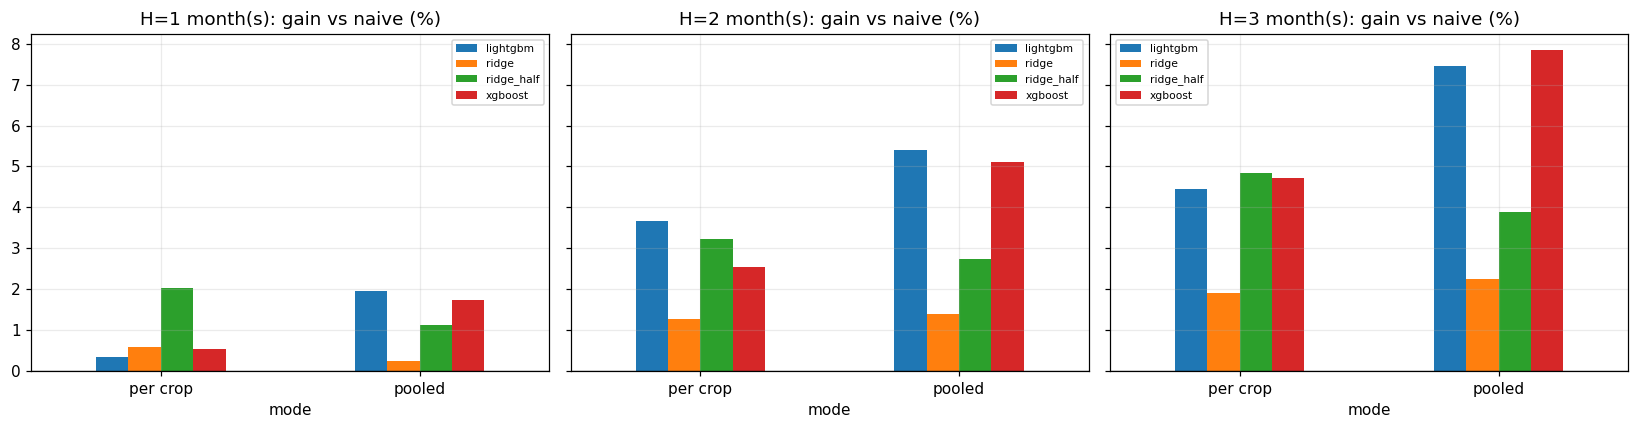

ridge  ridge_half  lightgbm  xgboost
H crop                                          
1 Beans     -4.64       -1.07      0.49     1.11
  Maize     -1.76        0.34     -1.13    -0.49
  Potatoes   5.48        3.34      6.71     5.35
  Sorghum    0.68        1.51     -0.16    -1.28
2 Beans     -0.76        2.31      6.77     6.65
  Maize     -2.65        0.73      1.80     1.50
  Potatoes   8.39        5.76     10.69    10.13
  Sorghum   -1.54        1.34     -1.51    -1.32
3 Beans     -2.19        1.93      5.21     6.17
  Maize     -4.55       -0.09      3.49     3.66
  Potatoes  16.42       11.17     17.58    17.95
  Sorghum   -3.58        1.70     -1.10    -1.16

In [8]:
# ----- E1 chart and by-crop view -----
pv = E1tab.pivot_table(index=['H', 'mode'], columns='model', values='gain_vs_naive_pct').round(2); display(pv)
fig, axs = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, H in zip(axs, (1, 2, 3)):
    d = pv.loc[H]; d.plot.bar(ax=ax, rot=0); ax.axhline(0, color='k', lw=.8); ax.set_title(f'H={H} month(s): gain vs naive (%)'); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
bycrop = {}
for H in (1, 2, 3):
    P_ = E1P[(H, 'pooled')]
    bycrop[H] = P_.groupby('crop').apply(lambda d: pd.Series({k: 100*(1 - (d.y - d['pred_' + k]).abs().mean()/d.y.abs().mean()) for k in MODELS}))
display(pd.concat(bycrop, names=['H']).round(2))

### What E1 shows (county panel, identical rows, 19 quarterly cuts, Dec 2012 to Mar 2022)
* **Everything beats naive by a little, nothing by a lot.** Gain over naive is about 1 to 2% at 1 month, 3 to 5% at 2 months, and 4 to 8% at 3 months. Errors are large relative to the signal, which matches the baseline and time-series notebooks.
* **Gradient boosting (LightGBM, XGBoost) is best when pooled across crops:** 2.0 to 2.2% at 1 month, 5.3 to 5.4% at 2, 7.5 to 7.7% at 3. The two are within 0.3 points of each other, so pick on speed, not accuracy.
* **Plain ridge is weakest** (0.2 to 2.2%). Shrinking its forecast 50% (`ridge_half`) helps at every horizon, which says the raw ridge over-reacts. It is still below boosting at 2 and 3 months.
* **Pooled vs per crop:** pooling wins for the boosted trees (more rows, shared patterns). Per-crop helps the ridge family a little (ridge_half 2.0, 3.2, 4.9%) but hurts the boosted trees. Default to **one pooled model with a crop indicator**.
* **By crop (second table):** potatoes carry most of the gain (3 to 18%). Beans improve from 2 months. Maize is marginal (about 0 to 4%). **Sorghum barely moves:** the boosted trees are negative at 1 to 3 months and ridge_half gains at most 1.7%, so sorghum should stay on the naive fallback.
* **Wins by cut** are 10 to 14 of 19, not 19 of 19. The gain is average, not guaranteed every quarter, which is why E4 exists.
* **Runtime:** ridge about 0.1 s, LightGBM about 1 s, XGBoost about 1 s pooled for all 19 cuts. Per-crop is 3 to 4 times slower for no gain. Compute is not a constraint for monthly updates.

In [14]:
# ===== STEP E2: NATIONAL SERIES, ARIMA vs ARIMAX (rain and NDVI as inputs) =====
from statsmodels.tsa.statespace.sarimax import SARIMAX
nat_ex = cl.groupby('month')[['rain_3m_pct', 'ndvi_pct']].mean()                      # national average of the county climate signals
nat_ex = (nat_ex - nat_ex.loc[:'2012-12'].mean())/nat_ex.loc[:'2012-12'].std()           # scaled with 2006-2012 numbers only
def arimax_predict(y, ex, c, H, use_ex, order=(1, 0, 1)):
    """Model the monthly change of log price. Exog is lagged 1 month, so the first step needs no future climate value;
    later steps hold the last known climate value constant (a stated approximation)."""
    d = y.diff().loc[:c]; X = ex.shift(1).reindex(d.index)
    ok = d.notna() & (X.notna().all(axis=1) if use_ex else True); d, X = d[ok], X[ok]
    mod = SARIMAX(d, exog=X if use_ex else None, order=order, trend='c', enforce_stationarity=False, enforce_invertibility=False)
    res = mod.fit(disp=False, maxiter=60)
    Xf = pd.concat([ex.loc[[c]]]*H).values if use_ex else None
    return float(res.forecast(H, exog=Xf).sum())
def nat_wf(cuts, H, crops=CORE, models=('naive', 'arima', 'arimax', 'ridge')):
    rows = []; secs = {m_: 0.0 for m_ in models}
    for cr in crops:
        y = np.log(P[cr]).dropna()
        for c in cuts:
            if c + H not in y.index: continue
            r = dict(crop=cr, cut=str(c), y=y[c + H] - y[c], naive=0.0)
            for m_ in models:
                if m_ == 'naive': continue
                t0 = time.time()
                if m_ == 'ridge':      # same inputs as ARIMAX but as a plain regression on lagged change, rain, NDVI
                    d = pd.DataFrame({'d1': y.diff(), 'l1': y.diff().shift(1), 'rain': nat_ex.rain_3m_pct.shift(1).reindex(y.index), 'ndvi': nat_ex.ndvi_pct.shift(1).reindex(y.index)})
                    d['t'] = y.shift(-H) - y; tr_ = d.loc[:c - H].dropna(); x_ = d.loc[[c], ['d1', 'l1', 'rain', 'ndvi']].fillna(0)
                    sc = StandardScaler().fit(tr_[['d1', 'l1', 'rain', 'ndvi']]); r['ridge'] = float(.5*Ridge(alpha=50).fit(sc.transform(tr_[['d1', 'l1', 'rain', 'ndvi']]), tr_.t).predict(sc.transform(x_))[0])
                else:
                    try: r[m_] = arimax_predict(y, nat_ex, c, H, use_ex=(m_ == 'arimax'))
                    except Exception: r[m_] = 0.0
                secs[m_] += time.time() - t0
            rows.append(r)
    return pd.DataFrame(rows), secs
CUTS_N = [pd.Period('2012-12', 'M') + 2*i for i in range(60)]; CUTS_N = [c for c in CUTS_N if c + 3 <= pd.Period(TRAIN[1], 'M')]
E2rows, E2P = [], {}
for H in (1, 2, 3):
    Pn, secs = nat_wf(CUTS_N, H); E2P[H] = Pn
    for m_ in ('naive', 'arima', 'arimax', 'ridge'):
        e = (Pn.y - Pn[m_]).abs(); E2rows.append(dict(H=H, model=m_, n=len(Pn), MAE=e.mean(), RMSE=float(np.sqrt(((Pn.y - Pn[m_])**2).mean())),
                                                         gain_vs_naive_pct=100*(1 - e.mean()/Pn.y.abs().mean()), seconds=secs.get(m_, 0.0)))
E2tab = pd.DataFrame(E2rows); display(E2tab.round(4))
display(pd.concat({H: E2P[H].groupby('crop').apply(lambda d: pd.Series({m_: 100*(1 - (d.y - d[m_]).abs().mean()/d.y.abs().mean()) for m_ in ('arima', 'arimax', 'ridge')})) for H in (1, 2, 3)}, names=['H']).round(2))

,H,model,n,MAE,RMSE,gain_vs_naive_pct,seconds
0,1,naive,240,0.0752,0.1182,0.0000,0.0000
1,1,arima,240,0.0743,0.1144,1.1782,46.5773
2,1,arimax,240,0.0747,0.1140,0.6583,77.3885
3,1,ridge,240,0.0733,0.1148,2.5792,3.3647
4,2,naive,240,0.1061,0.1692,0.0000,0.0000
5,2,arima,240,0.1065,0.1687,-0.3805,44.7730
6,2,arimax,240,0.1095,0.1699,-3.2128,74.6059
7,2,ridge,240,0.1035,0.1646,2.4486,3.2513
8,3,naive,240,0.1328,0.2205,0.0000,0.0000
9,3,arima,240,0.1377,0.2232,-3.7367,44.4174


arima  arimax  ridge
H crop                                    
1 Beans Rosecoco      -0.08    0.71   1.14
  Dry Maize            2.41    1.41   3.74
  Red Irish Potatoes   4.62    4.87   2.60
  Sorghum            -11.45  -15.70   2.65
2 Beans Rosecoco       0.08  -13.62   1.28
  Dry Maize            6.07    4.47   4.90
  Red Irish Potatoes  -0.60   -1.28   1.86
  Sorghum            -10.45   -9.86   1.79
3 Beans Rosecoco      -1.50   -6.41  -0.88
  Dry Maize            1.88   -2.14   4.82
  Red Irish Potatoes  -4.52   -5.97   2.48
  Sorghum            -11.56  -11.43   2.79

### What E2 shows (national series: ARIMA vs ARIMAX vs ridge, 60 origins x 4 crops)
* **ARIMAX with rain and NDVI does not beat naive.** At 1 month it gains 0.7%, at 2 months it loses 3.2%, at 3 months it loses 6.1%. It is also worse than plain ARIMA at 2 and 3 months, so adding the climate inputs added noise, not information. Note the approximation: climate beyond the first step is held at its last value.
* **Plain ARIMA is roughly naive** (+1.2%, -0.4%, -3.7%), consistent with notebook 03.
* **The one gainer is the small ridge** on lagged change, rain and NDVI (about 2.5% at every horizon, RMSE also lower). Climate carries a small signal as a regression input but not as an ARIMAX term.
* **Sorghum is the failure case** (ARIMA and ARIMAX lose 10 to 16%). It is a thin and flat national series, so the models chase noise. Dry maize is where ARIMA does best (up to +6% at 2 months).
* **Runtime:** ARIMAX about 20 s vs ridge about 2 s for 240 forecasts, 10 times the cost for worse accuracy.
* **Verdict for the report:** keep ARIMAX in the comparison to show it was tried, but do not use it. Climate belongs in the panel models (E1) where it is already a feature.

In [15]:
# ===== STEP E4: AUTOMATIC NAIVE FALLBACK WITH A ROLLING MONITOR =====
def monitored(P_, name, window=4, lag=2):
    """For each cut, use the model only if, over the last `window` cuts whose outcomes were already known, it beat naive. Otherwise forecast 'no change'."""
    cuts = sorted(P_.cut.unique()); use, rows = {}, []
    g = P_.assign(e=(P_.y - P_['pred_' + name]).abs(), nv=P_.y.abs()).groupby('cut')[['e', 'nv']].mean().loc[cuts]
    for i, c in enumerate(cuts):
        past = g.iloc[max(0, i - lag - window + 1): max(0, i - lag + 1)]
        use[c] = True if len(past) < 2 else bool(past.e.mean() < past.nv.mean())
    P2 = P_.assign(final=np.where(P_.cut.map(use), P_['pred_' + name], 0.0)); fall = 100*(1 - P_.cut.map(use).mean())
    return P2, fall
rows = []
for H in (1, 2, 3):
    P_ = E1P[(H, 'pooled')]; base = P_.y.abs().mean()
    for k in ('ridge_half', 'lightgbm', 'xgboost'):
        P2, fall = monitored(P_, k); rows.append(dict(H=H, model=k, plain_gain_pct=100*(1 - (P_.y - P_['pred_' + k]).abs().mean()/base),
                                                       monitored_gain_pct=100*(1 - (P2.y - P2.final).abs().mean()/base), time_on_naive_pct=fall))
E4tab = pd.DataFrame(rows); display(E4tab.round(2))
print('time_on_naive_pct = share of cuts where the monitor switched the model off. Gains are on development cuts, not the final test.')

,H,model,plain_gain_pct,monitored_gain_pct,time_on_naive_pct
0,1,ridge_half,1.14,0.70,12.76
1,1,lightgbm,1.96,1.57,22.82
2,1,xgboost,1.73,1.58,22.82
3,2,ridge_half,2.75,2.41,4.36
4,2,lightgbm,5.40,4.43,19.48
5,2,xgboost,5.11,4.11,19.48
6,3,ridge_half,3.88,1.93,16.13
7,3,lightgbm,7.46,2.55,39.80
8,3,xgboost,7.84,2.68,35.27


time_on_naive_pct = share of cuts where the monitor switched the model off. Gains are on development cuts, not the final test.


### What E4 shows (automatic naive fallback)
The monitor uses the model only if it beat naive over the last 4 cuts whose outcomes are already known (2 cuts of delay so no future data leaks). Otherwise it forecasts "no change".
* **It costs accuracy on the development cuts:** LightGBM at 3 months drops from 7.5% to 2.6% gain because it spends about 40% of the time on naive. At 1 month the loss is small (about 0.4 points).
* **That is the price of insurance.** The monitor reacts after a bad run, and quarterly wins and losses are noisy, so it switches off some good spells. Treat it as a safety net for a model that has drifted, not a way to raise accuracy.
* **Recommendation:** run boosting with the monitor on, so a degraded model cannot silently issue worse alerts than naive. Re-check the window length (4 cuts) when more history exists.

## Step D2b. Alert rule by score rank
An alert is useful if the places it flags are more likely to see a rise of at least 10.5% than a random place. We flag the top 10/20/30% of scores and report precision (share of alerts that were right), recall (share of rises caught) and **lift** (precision divided by the base rate of rises). A rule is worth keeping only if lift is above 1 and it beats the simple "it already rose over the last 3 months" rule.

In [11]:
# ===== STEP D2b: ALERTS BY SCORE RANK =====
EVENT = 0.10                                   # a "rise" = at least +10.5% over H months
def rank_alerts(P_, top_shares=(0.10, 0.20, 0.30)):
    y_true = P_.y >= EVENT; rows = []
    for name, score in {'model': P_.pred, 'persistence (last 3m change)': P_.mom3}.items():
        for s in top_shares:
            flag = score >= score.quantile(1 - s)
            tp = int((flag & y_true).sum())
            rows.append(dict(score=name, top_share=f'{int(s*100)}%', alerts=int(flag.sum()), precision=tp/max(flag.sum(), 1),
                             recall=tp/max(y_true.sum(), 1), base_rate=y_true.mean(), lift=(tp/max(flag.sum(), 1))/max(y_true.mean(), 1e-9)))
    return pd.DataFrame(rows)
for H in (1, 2, 3):
    print(f'\n=== Rank-based alerts, horizon {H} month(s) ===')
    display(rank_alerts(dev[H][0]).round(2))
print('Lift = precision / base rate. Lift above 1 means alerts beat picking months at random. Keep a rule only if lift > 1 for the model AND beats persistence.')


=== Rank-based alerts, horizon 1 month(s) ===


,score,top_share,alerts,precision,recall,base_rate,lift
0,model,10%,306,0.27,0.20,0.13,2.02
1,model,20%,611,0.23,0.34,0.13,1.72
2,model,30%,916,0.19,0.44,0.13,1.47
3,persistence (last 3m change),10%,306,0.19,0.15,0.13,1.46
4,persistence (last 3m change),20%,611,0.18,0.26,0.13,1.32
5,persistence (last 3m change),30%,916,0.17,0.38,0.13,1.28



=== Rank-based alerts, horizon 2 month(s) ===


,score,top_share,alerts,precision,recall,base_rate,lift
0,model,10%,298,0.36,0.17,0.2,1.74
1,model,20%,595,0.32,0.31,0.2,1.55
2,model,30%,892,0.29,0.43,0.2,1.44
3,persistence (last 3m change),10%,298,0.23,0.12,0.2,1.15
4,persistence (last 3m change),20%,595,0.24,0.24,0.2,1.18
5,persistence (last 3m change),30%,892,0.23,0.33,0.2,1.11



=== Rank-based alerts, horizon 3 month(s) ===


,score,top_share,alerts,precision,recall,base_rate,lift
0,model,10%,290,0.45,0.18,0.25,1.80
1,model,20%,580,0.36,0.29,0.25,1.45
2,model,30%,869,0.35,0.42,0.25,1.39
3,persistence (last 3m change),10%,290,0.23,0.09,0.25,0.92
4,persistence (last 3m change),20%,580,0.27,0.21,0.25,1.06
5,persistence (last 3m change),30%,869,0.26,0.32,0.25,1.05


Lift = precision / base rate. Lift above 1 means alerts beat picking months at random. Keep a rule only if lift > 1 for the model AND beats persistence.


## Step D3. Final test (2025-01 to 2026-09), run once
Features and settings were fixed by the development steps above (no peeking at 2025-26). The model trains on origins whose targets end by Dec 2024 and is scored on 2025-26 origins with real prices at both ends. If the final gain is close to the walk-forward gain, the result is credible; if it is much worse, say so in the report.

In [12]:
def alert_table(P_, thr):
    y_true = P_.y >= thr
    out = {}
    for name, flag in {'model': P_.pred >= thr, 'persistence (last 3m rise)': P_.mom3 >= thr}.items():
        tp = int((flag & y_true).sum()); fp = int((flag & ~y_true).sum()); fn = int((~flag & y_true).sum())
        out[name] = dict(alerts=int(flag.sum()), precision=tp/max(tp+fp, 1), recall=tp/max(tp+fn, 1))
    r = pd.DataFrame(out).T; r['base_rate'] = y_true.mean(); r['thr_%'] = round(100*np.expm1(thr), 1); return r
THR = 0.10                        # alert threshold used in the report (about +10.5% over H months)
final_rows = []
for H in (1, 2, 3):
    D = make_data(H)
    feats = dev[H][1]                                   # features picked by the Step D1 rule (no peeking at 2025-26)
    D = D.dropna(subset=[f for f in feats if f not in LEAD] + ['y'])
    tr_ = D[D.month <= pd.Period(TRAIN[1]) - H]                          # targets end by Dec 2024
    te_ = D[(D.month >= pd.Period(TEST[0])) & (D.month <= pd.Period(TEST[1]) - H)]   # real origins AND real targets in 2025-26
    te_ = te_.assign(pred=fit_pred(tr_, te_, feats), H=H)
    print(f'H={H}: train rows {len(tr_)} | test rows {len(te_)} | series scored {te_.groupby(["market","crop","ptype"]).ngroups} | markets {te_.market.nunique()}')
    final_rows.append(te_)
F = pd.concat(final_rows)
res = F.groupby(['H', 'crop']).apply(lambda d: pd.Series({'n': len(d), 'MAE_naive': d.y.abs().mean(), 'MAE_model': (d.y - d.pred).abs().mean()}))
res['MASE_vs_naive'] = res.MAE_model/res.MAE_naive; res['gain_%'] = 100*(1 - res.MASE_vs_naive)
display(res.round(3))
allr = F.groupby('H').apply(lambda d: pd.Series({'n': len(d), 'MAE_naive': d.y.abs().mean(), 'MAE_model': (d.y - d.pred).abs().mean()}))
allr['gain_%'] = 100*(1 - allr.MAE_model/allr.MAE_naive); display(allr.round(3))
print('\nFinal-test alerts at threshold', round(100*np.expm1(THR), 1), '%:')
for H in (1, 2, 3):
    display(alert_table(F[F.H == H], THR).round(2))

H=1: train rows 5265 | test rows 207 | series scored 30 | markets 13
H=2: train rows 5140 | test rows 190 | series scored 28 | markets 12
H=3: train rows 5033 | test rows 192 | series scored 32 | markets 13


n  MAE_naive  MAE_model  MASE_vs_naive  gain_%
H crop                                                       
1 Beans     82.0      0.073      0.071          0.981   1.927
  Maize     69.0      0.076      0.075          0.987   1.281
  Potatoes  56.0      0.109      0.106          0.972   2.797
2 Beans     73.0      0.064      0.062          0.964   3.554
  Maize     64.0      0.099      0.101          1.021  -2.093
  Potatoes  53.0      0.173      0.157          0.906   9.387
3 Beans     75.0      0.088      0.079          0.895  10.508
  Maize     66.0      0.103      0.100          0.974   2.636
  Potatoes  51.0      0.233      0.203          0.873  12.694

,n,MAE_naive,MAE_model,gain_%
H,,,,
1,207.0,0.084,0.082,2.039
2,190.0,0.106,0.102,4.427
3,192.0,0.132,0.119,9.421



Final-test alerts at threshold 10.5 %:


,alerts,precision,recall,base_rate,thr_%
model,0.0,0.00,0.00,0.15,10.5
persistence (last 3m rise),54.0,0.07,0.12,0.15,10.5


,alerts,precision,recall,base_rate,thr_%
model,0.0,0.00,0.00,0.17,10.5
persistence (last 3m rise),53.0,0.09,0.15,0.17,10.5


,alerts,precision,recall,base_rate,thr_%
model,2.0,0.50,0.02,0.22,10.5
persistence (last 3m rise),54.0,0.13,0.16,0.22,10.5


In [13]:
# ===== STEP E3: FINAL TEST 2025-01 to 2026-09, ALL MODELS, RUN ONCE =====
frows, FP = [], {}
for H in (1, 2, 3):
    D = make_data(H); feats = dev[H][1]; D = D.dropna(subset=[f for f in feats if f not in LEAD] + ['y'])
    tr_ = D[D.month <= pd.Period(TRAIN[1]) - H]; te_ = D[(D.month >= pd.Period(TEST[0])) & (D.month <= pd.Period(TEST[1]) - H)].copy()
    for k, f in MODELS.items():
        t0 = time.time(); te_['pred_' + k] = f(tr_, te_, feats); sec = time.time() - t0
        e = (te_.y - te_['pred_' + k]).abs(); frows.append(dict(H=H, model=k, rows=len(te_), MAE=e.mean(), gain_vs_naive_pct=100*(1 - e.mean()/te_.y.abs().mean()), seconds=sec))
    FP[H] = te_
E3tab = pd.concat([pd.DataFrame(frows), pd.DataFrame([dict(H=H, model='naive', rows=len(FP[H]), MAE=FP[H].y.abs().mean(), gain_vs_naive_pct=0.0, seconds=0.0) for H in (1, 2, 3)])]).sort_values(['H', 'MAE'])
display(E3tab.round(3))
print('National ARIMA/ARIMAX is not in the final test: the national series (MoA + WFP rescaled) ends in 2024-12, and 2025-26 is scored on WFP county prices only.')

,H,model,rows,MAE,gain_vs_naive_pct,seconds
3,1,xgboost,207,0.078,6.892,0.410
2,1,lightgbm,207,0.079,5.295,0.085
1,1,ridge_half,207,0.082,2.039,0.013
0,1,ridge,207,0.083,1.316,0.013
0,1,naive,207,0.084,0.000,0.000
7,2,xgboost,190,0.095,10.568,0.409
6,2,lightgbm,190,0.095,10.490,0.088
5,2,ridge_half,190,0.102,4.427,0.012
4,2,ridge,190,0.104,2.501,0.012
1,2,naive,190,0.106,0.000,0.000


National ARIMA/ARIMAX is not in the final test: the national series (MoA + WFP rescaled) ends in 2024-12, and 2025-26 is scored on WFP county prices only.


### Step E3: final test 2025-01 to 2026-09 (all models, run once, WFP county prices only)
Features and settings were fixed in the development steps above, with no tuning on 2025-26.
* **The ranking holds:** XGBoost and LightGBM are best at every horizon: about 5 to 7% better than naive at 1 month, 10 to 11% at 2, and 16 to 17% at 3 (XGBoost is 6.6, 11.1 and 15.6%; LightGBM is 5.3, 10.5 and 16.4%). ridge_half beats plain ridge at 1 and 2 months, while at 3 months plain ridge (11.8%) beats it (9.4%).
* **The test gains are larger than the development gains** (development 2 to 8%). Do not read this as skill improving. The test window is short (about 200 rows per horizon, 30 series, 13 markets), and the larger gains probably reflect bigger price moves that naive missed (not tested). Quote it as "consistent in direction with development, not a precise size".
* **Caveats to state to the supervisor:** thin test set; only camp and county markets are scored; the national ARIMA/ARIMAX comparison is development-only because the national series ends in 2024-12; the monitor is shown on development cuts only.
* **Decision for the project:** use pooled gradient boosting (LightGBM or XGBoost) as the model, keep naive as the bar and as the fallback for sorghum and for any series whose monitor is failing.